In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    confusion_matrix, classification_report
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Keep the CSV in the same folder as this notebook, or update this path.
DATA_PATH = "category.csv"

SCORE_HIGH, SCORE_MEDIUM, SCORE_LOW = 0.85, 0.55, 0.15
HIGH_CUTOFF = 0.7744
MEDIUM_CUTOFF = 0.6618

RANDOM_STATE = 42
TEST_SIZE = 0.20
CATEGORY_COL = "Clean_Category"

HIGH_CATEGORIES = [
    "Cafe", "Coaching Center", "Grocery Store", "Gym", "Repair service"
]
MEDIUM_CATEGORIES = [
    "Cell phone accessory store", "Dessert Shop", "Ice Cream Shop",
    "Restaurant", "Salon"
]
LOW_CATEGORIES = [
    "Apparel Shop", "Ayurvedic Store", "Dairy Shop", "Electrical", "Pharmacy"
]
ALL_MAPPED_CATEGORIES = set(
    HIGH_CATEGORIES + MEDIUM_CATEGORIES + LOW_CATEGORIES
)

In [2]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

required_columns = ["Clean_Category", "City", "Company"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

for col in required_columns:
    df[col] = df[col].astype(str).str.strip()

print("Dataset shape:", df.shape)
print("\\nMissing values:")
display(df.isna().sum().to_frame("Missing_Count"))
print("\\nClean_Category distribution:")
display(df[CATEGORY_COL].value_counts().rename_axis(CATEGORY_COL).to_frame("Count"))

unmapped = sorted(set(df[CATEGORY_COL]) - ALL_MAPPED_CATEGORIES)
if unmapped:
    raise ValueError(
        "These Clean_Category values have no priority rule. "
        f"Please map them before training: {unmapped}"
    )
print("All Clean_Category values are covered by the priority rules.")

Dataset shape: (193, 10)
\nMissing values:


,Missing_Count
S.No,0
Country,0
City,0
Company,0
CONTACT,0
Google Map,0
Category,0
Clean_Category,0
Rating,0
Review,0


\nClean_Category distribution:


,Count
Clean_Category,
Restaurant,162
Salon,5
Grocery Store,4
Repair service,3
Coaching Center,3
Gym,3
Dairy Shop,2
Cafe,2
Pharmacy,2


All Clean_Category values are covered by the priority rules.


In [3]:
def assign_rule_score(category):
    if category in HIGH_CATEGORIES:
        return SCORE_HIGH
    if category in MEDIUM_CATEGORIES:
        return SCORE_MEDIUM
    if category in LOW_CATEGORIES:
        return SCORE_LOW
    raise ValueError(f"Unmapped category: {category}")

df["Conversion_Probability"] = df[CATEGORY_COL].apply(assign_rule_score)

df["Rule_Priority"] = df["Conversion_Probability"].map({
    SCORE_HIGH: "High Priority",
    SCORE_MEDIUM: "Medium Priority",
    SCORE_LOW: "Low Priority"
})

display(
    df.groupby(["Rule_Priority", "Conversion_Probability"])
      .size().rename("Business_Count").reset_index()
)

,Rule_Priority,Conversion_Probability,Business_Count
0,High Priority,0.85,15
1,Low Priority,0.15,8
2,Medium Priority,0.55,170


In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["Conversion_Probability"]
)

train_df = train_df.copy()
test_df = test_df.copy()

print("Training rows:", len(train_df))
print("Testing rows :", len(test_df))
print("\\nTraining target distribution:")
display(train_df["Conversion_Probability"].value_counts().sort_index().rename("Count").to_frame())
print("\\nTesting target distribution:")
display(test_df["Conversion_Probability"].value_counts().sort_index().rename("Count").to_frame())

Training rows: 154
Testing rows : 39
\nTraining target distribution:


,Count
Conversion_Probability,
0.15,6
0.55,136
0.85,12


\nTesting target distribution:


,Count
Conversion_Probability,
0.15,2
0.55,34
0.85,3


## Leakage-safe feature engineering

In [5]:
# Learn mappings from TRAIN only
cat_freq_map = train_df[CATEGORY_COL].value_counts().to_dict()
city_freq_map = train_df["City"].value_counts().to_dict()

cat_encoder = {
    category: i
    for i, category in enumerate(sorted(train_df[CATEGORY_COL].unique()))
}
city_encoder = {
    city: i
    for i, city in enumerate(sorted(train_df["City"].unique()))
}

FEATURES = [
    "Company_Name_Length",
    "Company_Word_Count",
    "Category_Frequency",
    "City_Frequency",
    "Category_Encoded",
    "City_Encoded"
]

def build_features(data):
    out = pd.DataFrame(index=data.index)
    out["Company_Name_Length"] = data["Company"].str.len()
    out["Company_Word_Count"] = data["Company"].str.split().str.len()
    out["Category_Frequency"] = data[CATEGORY_COL].map(cat_freq_map).fillna(0)
    out["City_Frequency"] = data["City"].map(city_freq_map).fillna(0)
    out["Category_Encoded"] = data[CATEGORY_COL].map(cat_encoder).fillna(-1)
    out["City_Encoded"] = data["City"].map(city_encoder).fillna(-1)
    return out[FEATURES]

X_train = build_features(train_df)
y_train = train_df["Conversion_Probability"]

X_test = build_features(test_df)
y_test = test_df["Conversion_Probability"]

unseen_test_categories = sorted(set(test_df[CATEGORY_COL]) - set(cat_encoder))
unseen_test_cities = sorted(set(test_df["City"]) - set(city_encoder))

print("Unseen test categories:", unseen_test_categories or "None")
print("Unseen test cities:", unseen_test_cities or "None")
display(X_train.head())

Unseen test categories: ['Ayurvedic Store']
Unseen test cities: None


,Company_Name_Length,Company_Word_Count,Category_Frequency,City_Frequency,Category_Encoded,City_Encoded
4,17,2,129,37,12,7
25,34,4,129,41,12,2
136,13,2,129,4,12,4
43,24,4,129,10,12,5
37,17,3,129,41,12,2


## Training the Random Forest Regressor

In [6]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)

pred_test = rf.predict(X_test)

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print(f"Test R²   : {r2:.4f}")
print(f"Test MAE  : {mae:.4f}")
print(f"Test RMSE : {rmse:.4f}")

Test R²   : 0.8513
Test MAE  : 0.0149
Test RMSE : 0.0474


In [7]:
def assign_tier(score):
    if score > HIGH_CUTOFF:
        return "High Priority"
    if score > MEDIUM_CUTOFF:
        return "Medium Priority"
    return "Low Priority"

test_results = test_df[[
    "Clean_Category", "Conversion_Probability", "Rule_Priority"
]].copy()
test_results["Predicted_Probability"] = pred_test
test_results["Predicted_Priority"] = test_results["Predicted_Probability"].apply(assign_tier)

print("Test-set predicted priority distribution:")
display(test_results["Predicted_Priority"].value_counts().to_frame("Count"))

print("Rule priority vs model-predicted priority (test set):")
test_priority_check = pd.crosstab(
    test_results["Rule_Priority"],
    test_results["Predicted_Priority"]
).reindex(
    index=["High Priority", "Medium Priority", "Low Priority"],
    columns=["High Priority", "Medium Priority", "Low Priority"],
    fill_value=0
)
display(test_priority_check)

print("Regression-target tiers vs threshold-derived predicted tiers:")
print(classification_report(
    test_results["Rule_Priority"],
    test_results["Predicted_Priority"],
    labels=["High Priority", "Medium Priority", "Low Priority"],
    zero_division=0
))

Test-set predicted priority distribution:


,Count
Predicted_Priority,
Low Priority,36
High Priority,2
Medium Priority,1


Rule priority vs model-predicted priority (test set):


Predicted_Priority,High Priority,Medium Priority,Low Priority
Rule_Priority,,,
High Priority,2,1,0
Medium Priority,0,0,34
Low Priority,0,0,2


Regression-target tiers vs threshold-derived predicted tiers:
                 precision    recall  f1-score   support

  High Priority       1.00      0.67      0.80         3
Medium Priority       0.00      0.00      0.00        34
   Low Priority       0.06      1.00      0.11         2

       accuracy                           0.10        39
      macro avg       0.35      0.56      0.30        39
   weighted avg       0.08      0.10      0.07        39



## Feature importance

,Feature,Importance,Importance_%
0,Category_Encoded,0.461794,46.18
1,Category_Frequency,0.241373,24.14
2,City_Frequency,0.114894,11.49
3,Company_Name_Length,0.095415,9.54
4,City_Encoded,0.054079,5.41
5,Company_Word_Count,0.032445,3.24


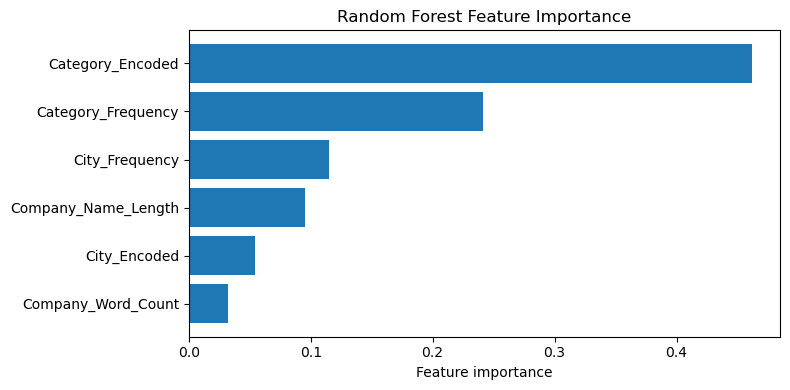

In [8]:
importance = (
    pd.DataFrame({
        "Feature": FEATURES,
        "Importance": rf.feature_importances_
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
importance["Importance_%"] = (importance["Importance"] * 100).round(2)
display(importance)

plt.figure(figsize=(8, 4))
plt.barh(importance["Feature"][::-1], importance["Importance"][::-1])
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## Businesses and summaries

In [9]:
result = df.copy()
result["Predicted_Probability"] = rf.predict(build_features(result)).round(4)
result["Priority"] = result["Predicted_Probability"].apply(assign_tier)
result["Data_Split"] = np.where(result.index.isin(test_df.index), "Test", "Train")

category_summary = (
    result.groupby(CATEGORY_COL)
    .agg(
        Businesses=("Company", "count"),
        Rule_Priority=("Rule_Priority", "first"),
        Training_Score=("Conversion_Probability", "first"),
        Avg_Predicted_Probability=("Predicted_Probability", "mean"),
        Min_Predicted_Probability=("Predicted_Probability", "min"),
        Max_Predicted_Probability=("Predicted_Probability", "max")
    )
    .round(4)
    .reset_index()
    .sort_values("Avg_Predicted_Probability", ascending=False)
)
display(category_summary)

print("Final predicted priority distribution across all records:")
display(result["Priority"].value_counts().to_frame("Count"))

,Clean_Category,Businesses,Rule_Priority,Training_Score,Avg_Predicted_Probability,Min_Predicted_Probability,Max_Predicted_Probability
12,Repair service,3,High Priority,0.85,0.8373,0.826,0.850
8,Grocery Store,4,High Priority,0.85,0.8270,0.816,0.843
9,Gym,3,High Priority,0.85,0.7900,0.788,0.791
2,Cafe,2,High Priority,0.85,0.7585,0.756,0.761
4,Coaching Center,3,High Priority,0.85,0.7453,0.718,0.761
3,Cell phone accessory store,1,Medium Priority,0.55,0.5880,0.588,0.588
14,Salon,5,Medium Priority,0.55,0.5500,0.550,0.550
13,Restaurant,162,Medium Priority,0.55,0.5494,0.510,0.556
10,Ice Cream Shop,1,Medium Priority,0.55,0.4880,0.488,0.488
6,Dessert Shop,1,Medium Priority,0.55,0.4150,0.415,0.415


Final predicted priority distribution across all records:


,Count
Priority,
Low Priority,178
High Priority,10
Medium Priority,5


## Export results and save the trained model

In [10]:
out_cols = [
    "S.No", "Country", "City", "Company", "CONTACT", "Google Map",
    "Category", "Clean_Category", "Rating", "Review",
    "Rule_Priority", "Conversion_Probability",
    "Predicted_Probability", "Priority", "Data_Split"
]
out_cols = [col for col in out_cols if col in result.columns]

final = result[out_cols].sort_values(
    ["Priority", "Predicted_Probability"],
    ascending=[True, False]
)

final.to_csv("lead_priority_results.csv", index=False)

with pd.ExcelWriter("lead_priority_results.xlsx") as writer:
    final.to_excel(writer, sheet_name="All Leads", index=False)
    final[final["Priority"] == "High Priority"].to_excel(
        writer, sheet_name="High Priority", index=False
    )
    final[final["Priority"] == "Medium Priority"].to_excel(
        writer, sheet_name="Medium Priority", index=False
    )
    final[final["Priority"] == "Low Priority"].to_excel(
        writer, sheet_name="Low Priority", index=False
    )
    category_summary.to_excel(writer, sheet_name="Category Summary", index=False)
    importance.to_excel(writer, sheet_name="Feature Importance", index=False)
    metrics = pd.DataFrame({
        "Metric": ["Train rows", "Test rows", "R2", "MAE", "RMSE"],
        "Value": [len(train_df), len(test_df), r2, mae, rmse]
    })
    metrics.to_excel(writer, sheet_name="Model Metrics", index=False)
    test_priority_check.to_excel(writer, sheet_name="Test Priority Check")

model_bundle = {
    "model": rf,
    "features": FEATURES,
    "category_frequency_map": cat_freq_map,
    "city_frequency_map": city_freq_map,
    "category_encoder": cat_encoder,
    "city_encoder": city_encoder,
    "high_categories": HIGH_CATEGORIES,
    "medium_categories": MEDIUM_CATEGORIES,
    "low_categories": LOW_CATEGORIES,
    "high_cutoff": HIGH_CUTOFF,
    "medium_cutoff": MEDIUM_CUTOFF
}
joblib.dump(model_bundle, "random_forest_lead_priority_model.joblib")

print("Saved:")
print("- lead_priority_results.csv")
print("- lead_priority_results.xlsx")
print("- random_forest_lead_priority_model.joblib")

Saved:
- lead_priority_results.csv
- lead_priority_results.xlsx
- random_forest_lead_priority_model.joblib
